<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **SpaceX  Falcon 9 First Stage Landing Prediction**


 ## Hands-on Lab: Complete the EDA with Visualization


Estimated time needed: **70** minutes


In this assignment, we will predict if the Falcon 9 first stage will land successfully. SpaceX advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is due to the fact that SpaceX can reuse the first stage. 

In this lab, you will perform Exploratory Data Analysis and Feature Engineering.


Falcon 9 first stage will land successfully


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planned. Space X performs a controlled landing in the oceans. 


  ## Objectives
Perform exploratory Data Analysis and Feature Engineering using `Pandas` and `Matplotlib`

- Exploratory Data Analysis
- Preparing Data  Feature Engineering 


----


Install the below libraries


In [1]:
# Run this cell first (or choose Kernel > Restart & Run All).
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

candidates = [Path('dataset_part_2.csv'), Path('dataset_part_2 (1).csv')]
source = next((p for p in candidates if p.exists()), None)
if source is None:
    raise FileNotFoundError('Upload dataset_part_2.csv to the same Jupyter folder as this notebook.')
df = pd.read_csv(source)
print(f'Loaded {source}: {df.shape[0]} rows, {df.shape[1]} columns')
display(df.head(3))


<ipython-input-1-1e44a458e726>:3: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


Loaded dataset_part_2.csv: 90 rows, 18 columns


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0


### Import Libraries and Define Auxiliary Functions


We will import the following libraries the lab 



In [ ]:
# andas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
#NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np
# Matplotlib is a plotting library for python and pyplot gives us a MatLab like plotting framework. We will use this in our plotter function to plot data.
import matplotlib.pyplot as plt
#Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics
 # Seaborn is optional; all charts below use Matplotlib.

## Exploratory Data Analysis 


First, let's read the SpaceX dataset into a Pandas dataframe and print its summary


In [ ]:
# Dataset was loaded in the setup cell above.
# This cell is safe to rerun if you already executed the setup.
print('Launch records ready for visualization:', df.shape)


First, let's try to see how the `FlightNumber` (indicating the continuous launch attempts.) and `Payload` variables would affect the launch outcome.

We can plot out the <code>FlightNumber</code> vs. <code>PayloadMass</code>and overlay the outcome of the launch. We see that as the flight number increases, the first stage is more likely to land successfully. The payload mass is also important; it seems the more massive the payload, the less likely the first stage will return.


In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
for outcome, color, label in [(0, 'tomato', 'Unsuccessful'), (1, 'seagreen', 'Successful')]:
    subset = df[df['Class'] == outcome]
    ax.scatter(subset['FlightNumber'], subset['PayloadMass'], c=color, label=label, alpha=0.75, s=45)
ax.set_xlabel('FlightNumber')
ax.set_ylabel('PayloadMass')
ax.set_title('Payload Mass vs Flight Number')
ax.legend(title='Landing outcome')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Next, let's drill down to each site visualize its detailed launch records.


### TASK 1: Visualize the relationship between Flight Number and Launch Site


Use the function <code>catplot</code> to plot <code>FlightNumber</code> vs <code>LaunchSite</code>, set the  parameter <code>x</code>  parameter to <code>FlightNumber</code>,set the  <code>y</code> to <code>Launch Site</code> and set the parameter <code>hue</code> to <code>'class'</code>


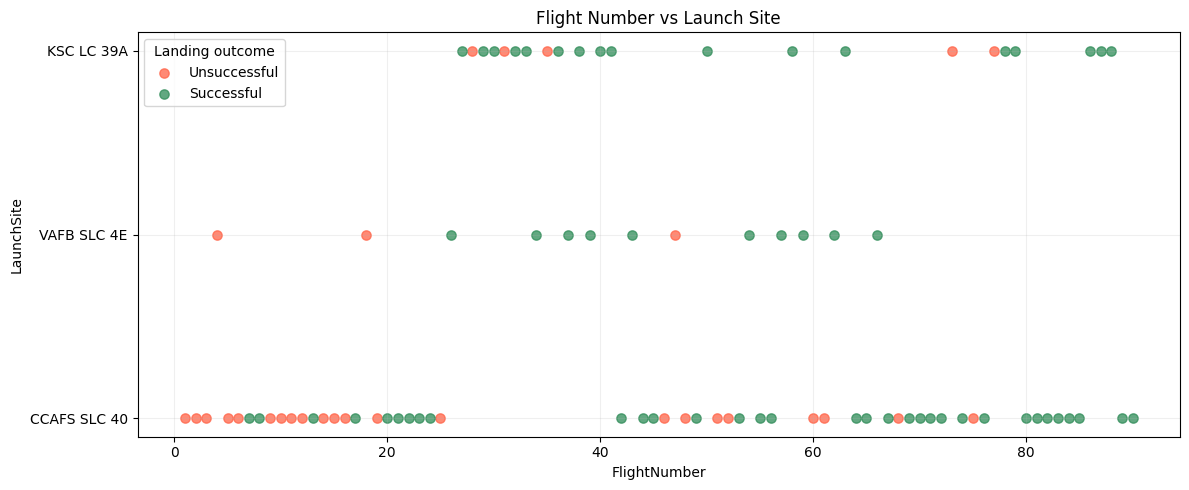

In [2]:
fig, ax = plt.subplots(figsize=(12, 5))
for outcome, color, label in [(0, 'tomato', 'Unsuccessful'), (1, 'seagreen', 'Successful')]:
    subset = df[df['Class'] == outcome]
    ax.scatter(subset['FlightNumber'], subset['LaunchSite'], c=color, label=label, alpha=0.75, s=45)
ax.set_xlabel('FlightNumber')
ax.set_ylabel('LaunchSite')
ax.set_title('Flight Number vs Launch Site')
ax.legend(title='Landing outcome')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Now try to explain the patterns you found in the Flight Number vs. Launch Site scatter point plots.


### TASK 2: Visualize the relationship between Payload and Launch Site


We also want to observe if there is any relationship between launch sites and their payload mass.


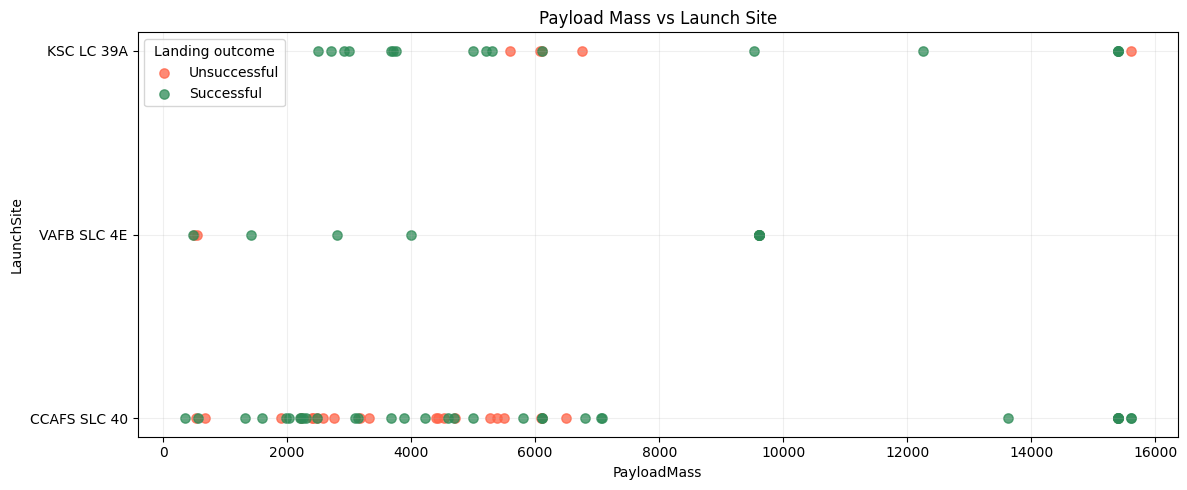

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))
for outcome, color, label in [(0, 'tomato', 'Unsuccessful'), (1, 'seagreen', 'Successful')]:
    subset = df[df['Class'] == outcome]
    ax.scatter(subset['PayloadMass'], subset['LaunchSite'], c=color, label=label, alpha=0.75, s=45)
ax.set_xlabel('PayloadMass')
ax.set_ylabel('LaunchSite')
ax.set_title('Payload Mass vs Launch Site')
ax.legend(title='Landing outcome')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Now if you observe Payload Vs. Launch Site scatter point chart you will find for the VAFB-SLC  launchsite there are no  rockets  launched for  heavypayload mass(greater than 10000).


### TASK  3: Visualize the relationship between success rate of each orbit type


Next, we want to visually check if there are any relationship between success rate and orbit type.


Let's create a `bar chart` for the sucess rate of each orbit


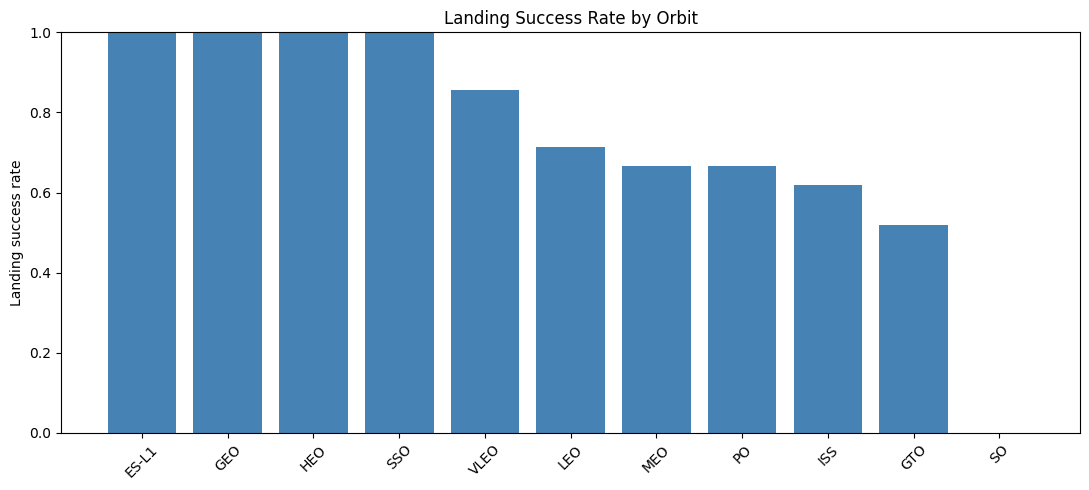

,Orbit,Class
0,ES-L1,1.000000
1,GEO,1.000000
3,HEO,1.000000
9,SSO,1.000000
10,VLEO,0.857143
5,LEO,0.714286
6,MEO,0.666667
7,PO,0.666667
4,ISS,0.619048
2,GTO,0.518519


In [4]:
orbit_success = df.groupby('Orbit', as_index=False)['Class'].mean().sort_values('Class', ascending=False)
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(orbit_success['Orbit'], orbit_success['Class'], color='steelblue')
ax.set_ylabel('Landing success rate')
ax.set_title('Landing Success Rate by Orbit')
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()
display(orbit_success)


Analyze the ploted bar chart try to find which orbits have high sucess rate.


### TASK  4: Visualize the relationship between FlightNumber and Orbit type


For each orbit, we want to see if there is any relationship between FlightNumber and Orbit type.


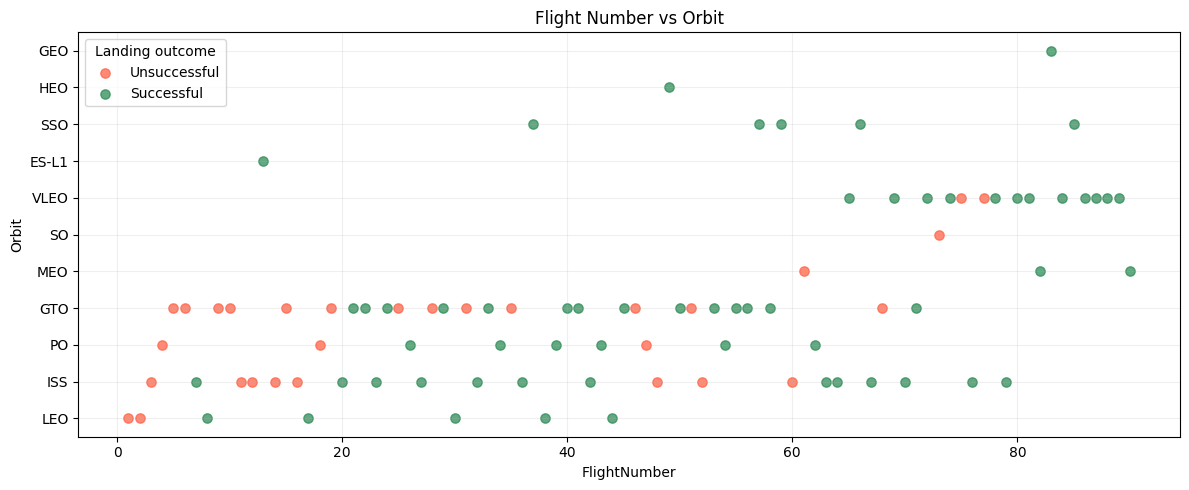

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
for outcome, color, label in [(0, 'tomato', 'Unsuccessful'), (1, 'seagreen', 'Successful')]:
    subset = df[df['Class'] == outcome]
    ax.scatter(subset['FlightNumber'], subset['Orbit'], c=color, label=label, alpha=0.75, s=45)
ax.set_xlabel('FlightNumber')
ax.set_ylabel('Orbit')
ax.set_title('Flight Number vs Orbit')
ax.legend(title='Landing outcome')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


You should see that in the LEO orbit the Success appears related to the number of flights; on the other hand, there seems to be no relationship between flight number when in GTO orbit.


### TASK  5: Visualize the relationship between Payload and Orbit type


Similarly, we can plot the Payload vs. Orbit scatter point charts to reveal the relationship between Payload and Orbit type


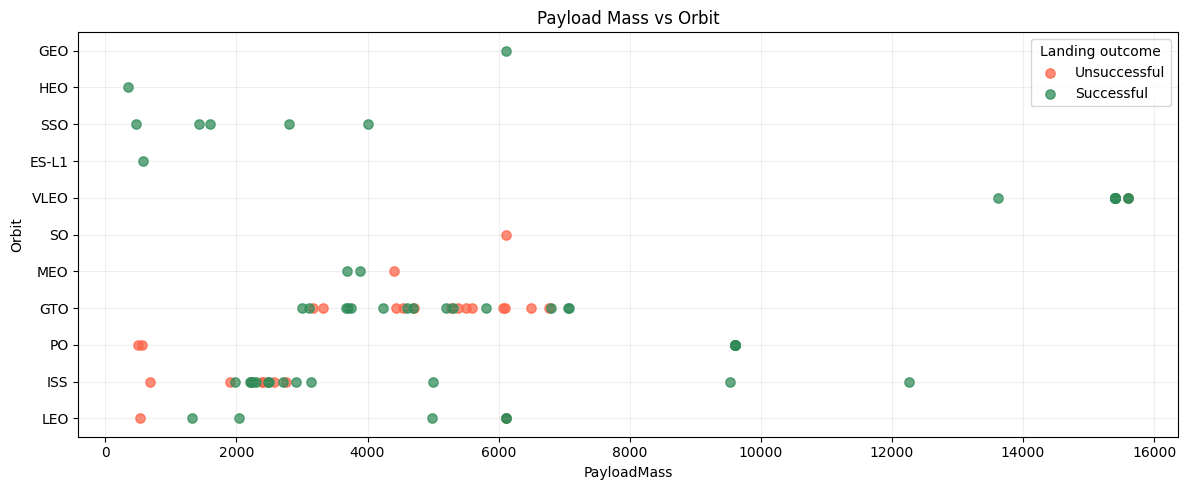

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
for outcome, color, label in [(0, 'tomato', 'Unsuccessful'), (1, 'seagreen', 'Successful')]:
    subset = df[df['Class'] == outcome]
    ax.scatter(subset['PayloadMass'], subset['Orbit'], c=color, label=label, alpha=0.75, s=45)
ax.set_xlabel('PayloadMass')
ax.set_ylabel('Orbit')
ax.set_title('Payload Mass vs Orbit')
ax.legend(title='Landing outcome')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


With heavy payloads the successful landing or positive landing rate are more for Polar,LEO and ISS.   

However for GTO we cannot distinguish this well as both positive landing rate and negative landing(unsuccessful mission) are both there here.




### TASK  6: Visualize the launch success yearly trend


You can plot a line chart with x axis to be <code>Year</code> and y axis to be average success rate, to get the average launch success trend. 


The function will help you get the year from the date:


In [7]:
# Extract calendar year without accumulating duplicate values on repeated runs.
def Extract_year(date):
    return pd.to_datetime(date).dt.year.tolist()
year = Extract_year(df['Date'])

In [ ]:
df['Year'] = pd.to_datetime(df['Date']).dt.year
yearly_success = df.groupby('Year', as_index=False)['Class'].mean()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly_success['Year'], yearly_success['Class'], marker='o')
ax.set_ylim(0, 1)
ax.set_ylabel('Average landing success rate')
ax.set_xlabel('Year')
ax.set_title('Yearly Landing Success Trend')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
display(yearly_success)


You can observe that the success rate since 2013 kept increasing till 2017 (stable in 2014) and after 2015 it started increasing.


## Features Engineering 


By now, you should obtain some preliminary insights about how each important variable would affect the success rate, we will select the features that will be used in success prediction in the future module.


In [ ]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features.head()

 ### TASK  7: Create dummy variables to categorical columns


Use the function <code>get_dummies</code> and <code>features</code> dataframe to apply OneHotEncoder to the column <code>Orbits</code>, <code>LaunchSite</code>, <code>LandingPad</code>, and <code>Serial</code>. Assign the value to the variable <code>features_one_hot</code>, display the results using the method head. Your result dataframe must include all features including the encoded ones.


In [ ]:
features_one_hot = pd.get_dummies(features,columns=['Orbit','LaunchSite','LandingPad','Serial'],dummy_na=False)
display(features_one_hot.head())
print('Feature columns:',features_one_hot.shape[1])

### TASK  8: Cast all numeric columns to `float64`


Now that our <code>features_one_hot</code> dataframe only contains numbers cast the entire dataframe to variable type <code>float64</code>


In [ ]:
features_one_hot = features_one_hot.astype('float64')
print(features_one_hot.dtypes.value_counts())
features_one_hot.to_csv('dataset_part_3.csv',index=False)
print('Saved dataset_part_3.csv:',features_one_hot.shape)

We can now export it to a <b>CSV</b> for the next section,but to make the answers consistent, in the next lab we will provide data in a pre-selected date range. 


<code>features_one_hot.to_csv('dataset_part_3.csv', index=False)</code>


## Authors


<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.


<a href="https://www.linkedin.com/in/nayefaboutayoun/">Nayef Abou Tayoun</a> is a Data Scientist at IBM and pursuing a Master of Management in Artificial intelligence degree at Queen's University.


## Change Log


| Date (YYYY-MM-DD) | Version | Changed By | Change Description      |
| ----------------- | ------- | ---------- | ----------------------- |
| 2021-10-12        | 1.1     | Lakshmi Holla     | Modified markdown |
| 2020-09-20        | 1.0     | Joseph     | Modified Multiple Areas |
| 2020-11-10       | 1.1    | Nayef      | updating the input data |


Copyright © 2020 IBM Corporation. All rights reserved.
